In [1]:
## unzip files
# !unzip -q hw5.zip
# %cd hw5

# after restarting the kernel, make sure the files are still available
%cd /content/hw5
!ls


/content/hw5
data.py      gpt     main.py	__pycache__	  sbatch.sh
generate.py  hw5.md  model.pth	requirements.txt  test_sbatch.sh


In [2]:
import torch

In [3]:
# confirming gpu access
print(torch.cuda.is_available(), torch.cuda.get_device_name(0))

True Tesla T4


In [4]:
## install requirements
# !pip install -q -r requirements.txt # this errored so tried directly below
# !pip install -q datasets==2.17.1 matplotlib==3.8.3 regex==2023.12.25 transformers==4.37.1 tqdm==4.66.2 Requests==2.31.0

In [5]:
# there was an error with jax being installed and the use fo th downgraded version of numpy so I'm removing it
# !pip uninstall -y jax jaxlib

In [6]:
# after restarting kernel, verify that packages still installed
import numpy, torch, datasets, transformers
print(numpy.__version__, torch.__version__, torch.cuda.is_available())

The cache for model files in Transformers v4.22.0 has been updated. Migrating your old cache. This is a one-time only operation. You can interrupt this and resume the migration later on by calling `transformers.utils.move_cache()`.


0it [00:00, ?it/s]

1.26.4 2.11.0+cu130 True


In [7]:
# !pip install -q "huggingface_hub==0.36.2"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
transformers 5.20.2 requires huggingface-hub<3.0,>=1.31.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.41.0 requires huggingface-hub<2.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [7]:
# run the cpu vs gpu comparison
from main import *

train_data, dev_data = load_data()
train_d, dev_d = create_datasets(train_data, dev_data, block_size=32)
cpu_gpu_comparison(train_d, dev_d, max_iter=50)

---------- Load Dataset ----------


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/1801350 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

100%|██████████| 3760/3760 [00:00<00:00, 100374.13it/s]


number of parameters: 2.50M
running on device cpu
iter 0: validation loss 10.82717 validation ppl 50371.097
best model so far, saving...
iter_dt 0.00s; iter 0: train loss 10.82659 train ppl 50341.969
---------- Trainer Time Elapsed: 130.21s ----------

number of parameters: 2.50M
running on device cuda
iter 0: validation loss 10.83561 validation ppl 50798.110
best model so far, saving...
iter_dt 0.00s; iter 0: train loss 10.83610 train ppl 50822.766
---------- Trainer Time Elapsed: 8.31s ----------



In [4]:
import os
os.environ["USE_FLAX"] = "0"
%cd /content/hw5

%matplotlib inline
import matplotlib.pyplot as plt

# Save every figure at the moment it's shown, in case plot() only calls plt.show()
_orig_show = plt.show
def save_and_show(*a, **k):
    for n in plt.get_fignums():
        plt.figure(n).savefig(f"/content/hw5/plot_{n}.png", dpi=150, bbox_inches="tight")
    _orig_show(*a, **k)
plt.show = save_and_show

from main import *
train_data, dev_data = load_data()
train_d, dev_d = create_datasets(train_data, dev_data, block_size=32)

/content/hw5
---------- Load Dataset ----------


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(
100%|██████████| 3760/3760 [00:00<00:00, 102939.13it/s]


number of parameters: 2.50M
running on device cuda
iter 0: validation loss 10.82717 validation ppl 50371.095
best model so far, saving...
iter_dt 0.00s; iter 0: train loss 10.82925 train ppl 50475.852
iter_dt 15.63s; iter 100: train loss 8.34511 train ppl 4209.537
iter_dt 15.80s; iter 200: train loss 7.16262 train ppl 1290.289
iter_dt 15.84s; iter 300: train loss 6.61846 train ppl 748.791
iter_dt 15.79s; iter 400: train loss 6.30814 train ppl 549.021
iter_dt 15.98s; iter 500: train loss 6.12118 train ppl 455.401
iter_dt 16.15s; iter 600: train loss 5.85887 train ppl 350.330
iter_dt 16.17s; iter 700: train loss 5.76829 train ppl 319.989
iter_dt 16.12s; iter 800: train loss 5.80220 train ppl 331.027
iter_dt 16.16s; iter 900: train loss 5.67806 train ppl 292.381
iter 1000: validation loss 5.66591 validation ppl 293.508
best model so far, saving...
iter_dt 16.35s; iter 1000: train loss 5.84424 train ppl 345.240
iter_dt 16.45s; iter 1100: train loss 5.76362 train ppl 318.499
iter_dt 16.39s;

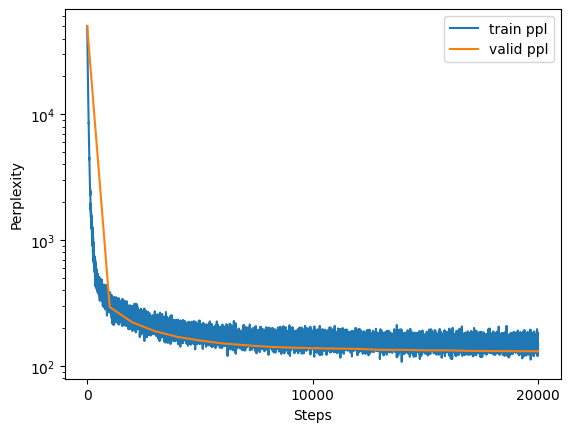

In [5]:
gpu_full_run(train_d, dev_d, max_iter=20000)

-rw-r--r-- 1 root root 26851 Oct 25 18:20 /content/hw5/loss.png
-rw-r--r-- 1 root root 27272 Oct 25 18:20 /content/hw5/ppl.png


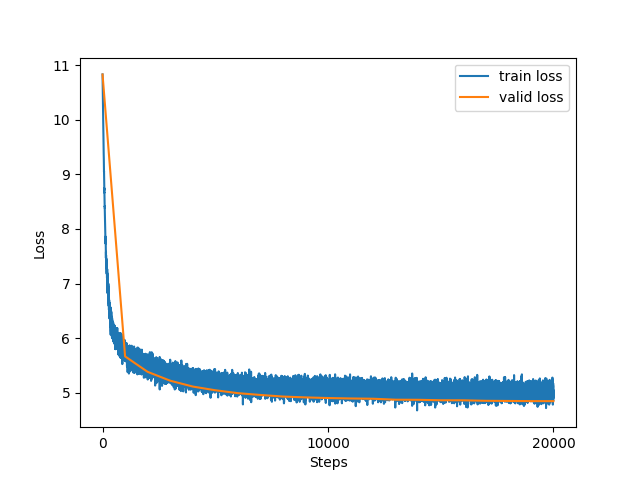

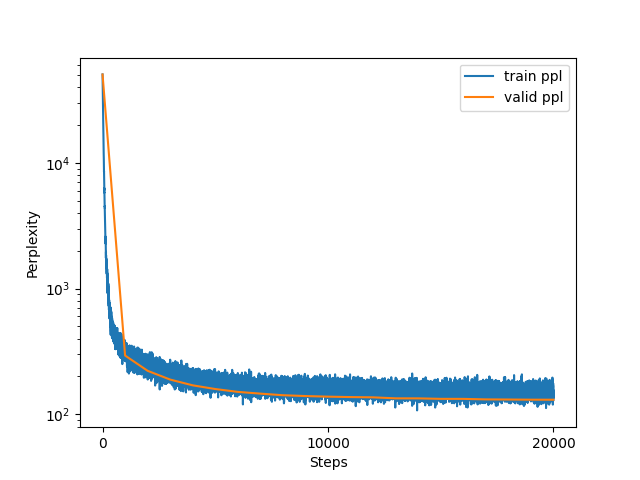

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:
!ls -l /content/hw5/loss.png /content/hw5/ppl.png

from IPython.display import Image, display
display(Image("/content/hw5/loss.png"))
display(Image("/content/hw5/ppl.png"))

from google.colab import files
files.download("/content/hw5/loss.png")
files.download("/content/hw5/ppl.png")